
# MODULE 6: DIMENSIONALITY REDUCTION

**Student Name:** AYUSH KUMAR YADAV  
**Registration Number:** 23BDS0333  
**Dataset:** Lithium-Ion Battery Materials  
**Phase:** 3

## Introduction

Dimensionality reduction transforms a dataset with many features into a smaller feature space while retaining useful information.

This notebook applies Principal Component Analysis (PCA), Singular Value Decomposition (SVD), Factor Analysis, and intrinsic dimensionality estimation to numerical properties of lithium-ion battery materials.

## Objectives

1. Load and preprocess the battery materials dataset.
2. Select and standardize numerical features.
3. Apply PCA and examine explained variance.
4. Estimate the number of components required to retain 90% variance.
5. Visualize the data in two and three dimensions.
6. Apply SVD and Factor Analysis.
7. Estimate intrinsic dimensionality and compare the results.

## Expected Outcome

Understand how dimensionality reduction can summarize material properties such as formation energy, energy above hull, band gap, number of sites, density, and volume.


MODULE 6: DIMENSIONALITY REDUCTION
Dataset loaded from: C:\Users\anind\EDA_PROJECT_23BDS0333\PHASE_1\lithium_ion_23BDS0333.csv
Dataset shape: (339, 11)


,Materials Id,Formula,Spacegroup,Formation Energy (eV),E Above Hull (eV),Band Gap (eV),Nsites,Density (gm/cc),Volume,Has Bandstructure,Crystal System
0,mp-849394,Li2MnSiO4,Pc,-2.699,0.006,3.462,16,2.993,178.513,True,monoclinic
1,mp-783909,Li2MnSiO4,P21/c,-2.696,0.008,2.879,32,2.926,365.272,True,monoclinic
2,mp-761311,Li4MnSi2O7,Cc,-2.775,0.012,3.653,28,2.761,301.775,True,monoclinic
3,mp-761598,Li4Mn2Si3O10,C2/c,-2.783,0.013,3.015,38,2.908,436.183,True,monoclinic
4,mp-767709,Li2Mn3Si3O10,C2/c,-2.747,0.016,2.578,36,3.334,421.286,True,monoclinic



Selected features: ['formation_energy_ev', 'e_above_hull_ev', 'band_gap_ev', 'nsites', 'density_gm_cc', 'volume']
Feature count: 6
Rows used: 339

PRINCIPAL COMPONENT ANALYSIS
Components required for 90% variance: 4


,Component,Explained Variance Ratio,Cumulative Variance
0,1,0.4146,0.4146
1,2,0.2784,0.6930
2,3,0.1581,0.8511
3,4,0.0845,0.9355
4,5,0.0625,0.9981
5,6,0.0019,1.0000


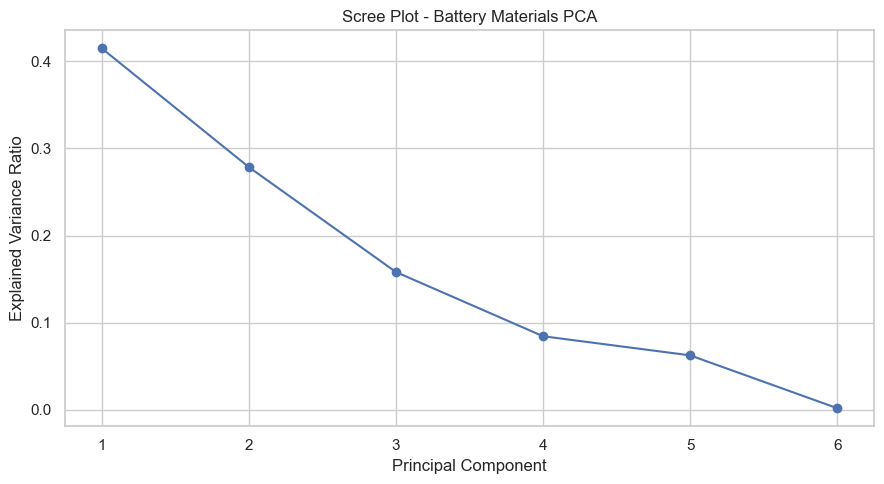

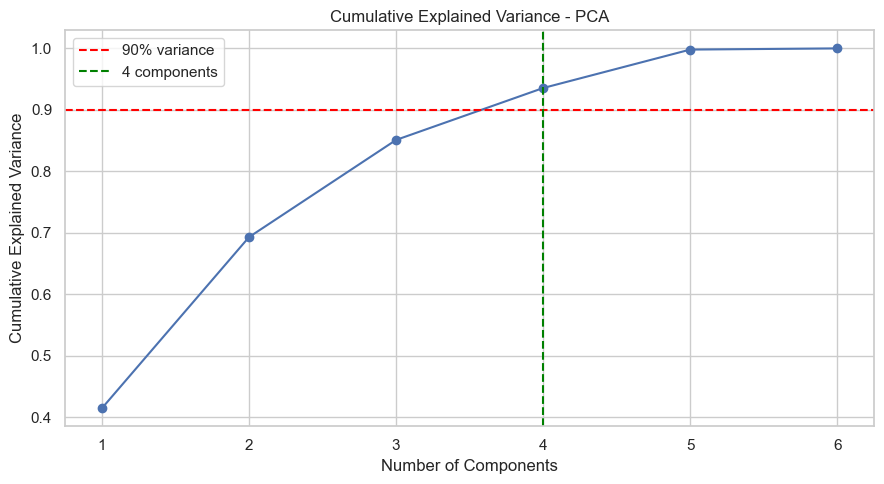

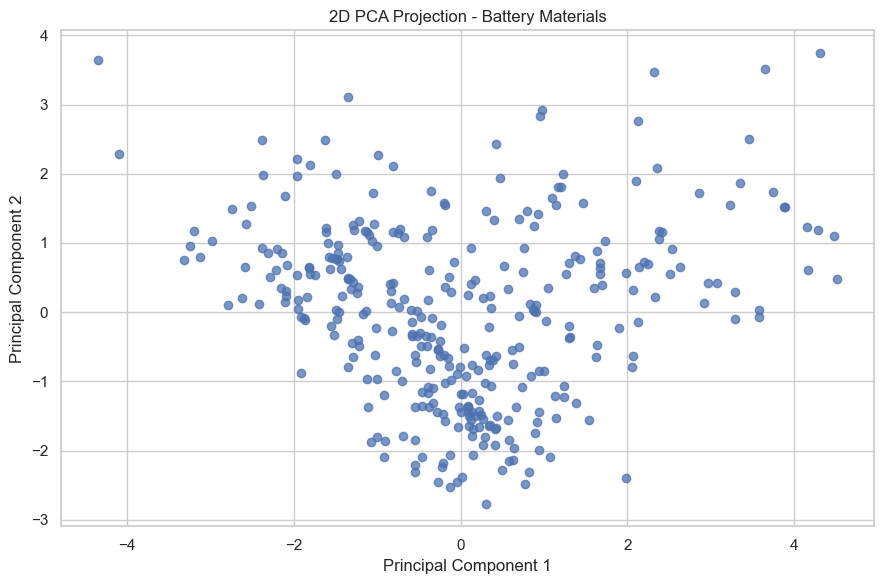


Variance retained by 2D PCA: 69.3 %


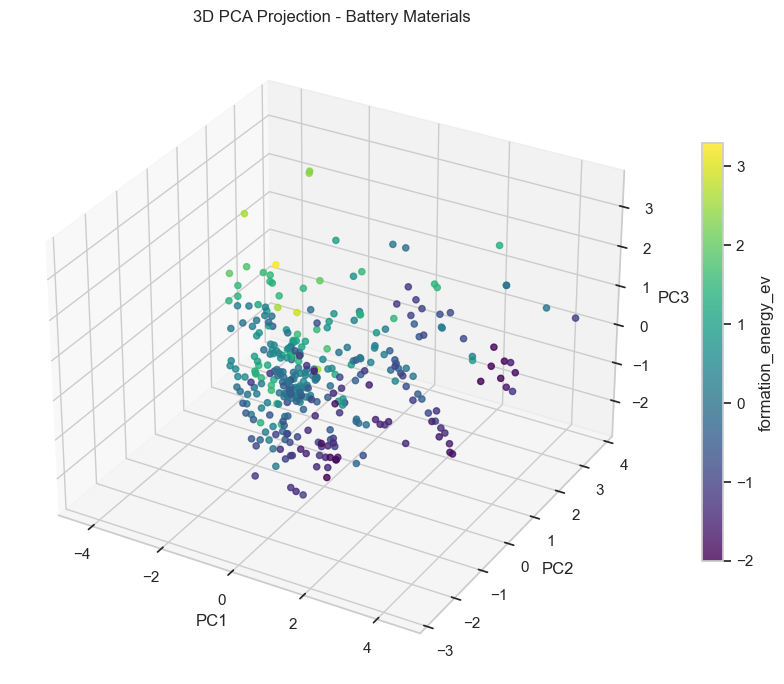

Variance retained by 3D PCA: 85.11 %

PCA Feature Loadings:


,PC1,PC2
formation_energy_ev,-0.4497,0.2815
e_above_hull_ev,-0.1338,0.5525
band_gap_ev,0.3521,-0.4845
nsites,0.4877,0.4346
density_gm_cc,-0.3878,0.1422
volume,0.5174,0.4143


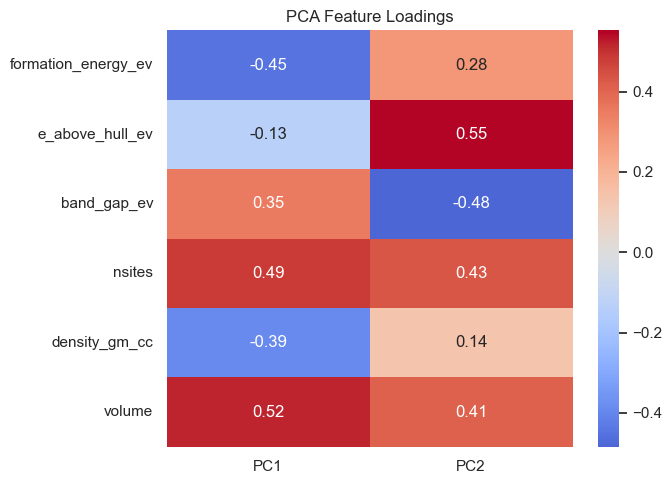

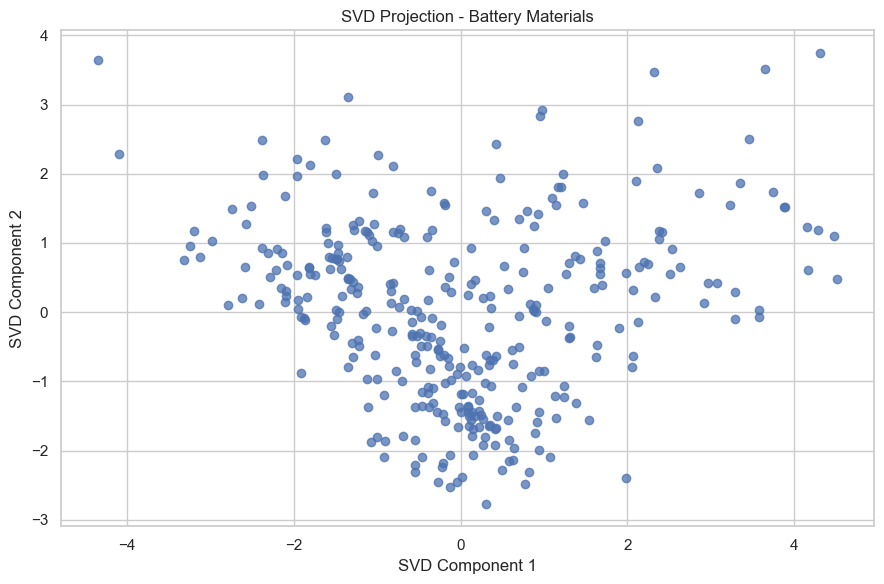

Variance retained by 2D SVD: 69.3 %

Factor Analysis score shape: (339, 2)

Factor Loadings:


,Factor 1,Factor 2
formation_energy_ev,-0.2968,0.4646
e_above_hull_ev,0.0821,0.0492
band_gap_ev,0.1350,-0.3949
nsites,0.9902,0.0798
density_gm_cc,-0.2526,0.8750
volume,0.9938,-0.0463


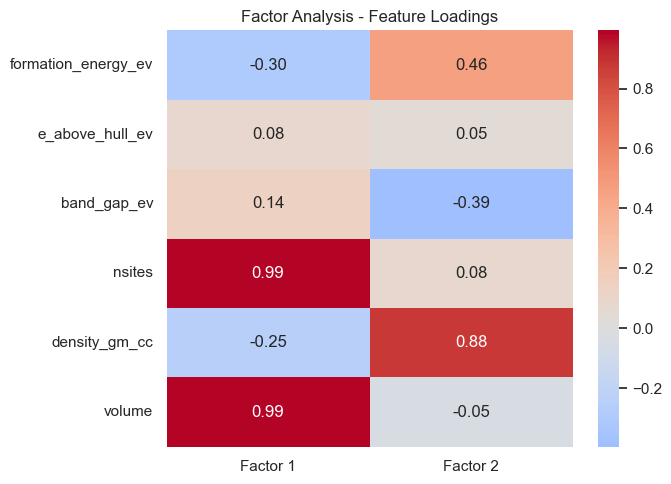


INTRINSIC DIMENSIONALITY
Original numerical feature count: 6
Components needed for 90% variance: 4
Estimated effective dimensionality: 3.5

DIMENSIONALITY REDUCTION COMPARISON


,Method,Components,Variance Explained (%)
0,PCA (2D),2,69.30
1,PCA (3D),3,85.11
2,SVD (2D),2,69.30
3,Factor Analysis,2,NaN



PCA results saved to: C:\Users\anind\EDA_PROJECT_23BDS0333\PHASE_3\lithium_ion_pca_results.csv

MODULE 6 COMPLETED SUCCESSFULLY


In [1]:

# ==========================================================
# MODULE 6: DIMENSIONALITY REDUCTION
# Student: AYUSH KUMAR YADAV
# Registration: 23BDS0333
# Dataset: Lithium-Ion Battery Materials
# ==========================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, TruncatedSVD, FactorAnalysis
from sklearn.impute import SimpleImputer

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# ----------------------------------------------------------
# 1. FIND AND LOAD DATASET
# ----------------------------------------------------------

possible_paths = [
    "../Phase 1/lithium_ion_cleaned.csv",
    "Phase 1/lithium_ion_cleaned.csv",
    "lithium_ion_cleaned.csv",
    "../Phase 1/lithium_ion_23BDS0333.csv",
    "Phase 1/lithium_ion_23BDS0333.csv",
    "lithium_ion_23BDS0333.csv",
    "../Phase 2/lithium_ion_cleaned.csv",
    "Phase 2/lithium_ion_cleaned.csv",
    "../Phase 1/lithium_ion_transformed.csv",
    "Phase 1/lithium_ion_transformed.csv"
]

file_path = next(
    (p for p in possible_paths if os.path.isfile(p)),
    None
)

# Search current and parent directories if needed
if file_path is None:
    for root in [os.getcwd(), os.path.dirname(os.getcwd())]:
        for folder, _, files in os.walk(root):
            match = next(
                (
                    name for name in files
                    if name.lower() in {
                        "lithium_ion_cleaned.csv",
                        "lithium_ion_23bds0333.csv"
                    }
                ),
                None
            )
            if match:
                file_path = os.path.join(folder, match)
                break
        if file_path:
            break

if file_path is None:
    raise FileNotFoundError(
        "Lithium-Ion CSV not found. Place "
        "'lithium_ion_cleaned.csv' or "
        "'lithium_ion_23BDS0333.csv' in the Phase 1 folder."
    )

df = pd.read_csv(file_path)

print("=" * 65)
print("MODULE 6: DIMENSIONALITY REDUCTION")
print("=" * 65)
print("Dataset loaded from:", os.path.abspath(file_path))
print("Dataset shape:", df.shape)
display(df.head())

# ----------------------------------------------------------
# 2. SELECT NUMERICAL FEATURES
# Exclude Materials Id and Formula because they are identifiers.
# ----------------------------------------------------------

candidate_features = [
    "formation_energy_ev",
    "e_above_hull_ev",
    "band_gap_ev",
    "nsites",
    "density_gm_cc",
    "volume"
]

# Support original dataset column names as well
column_lookup = {
    str(col).strip().lower()
    .replace(" ", "_")
    .replace("(", "")
    .replace(")", "")
    .replace("/", "_"): col
    for col in df.columns
}

feature_map = {
    "formation_energy_ev": [
        "formation_energy_ev", "formation_energy_ev_"
    ],
    "e_above_hull_ev": [
        "e_above_hull_ev", "e_above_hull_ev_"
    ],
    "band_gap_ev": ["band_gap_ev", "band_gap_ev_"],
    "nsites": ["nsites"],
    "density_gm_cc": ["density_gm_cc", "density_gm_cc_"],
    "volume": ["volume"]
}

selected_columns = {}

for standard_name, aliases in feature_map.items():
    for alias in aliases:
        if alias in column_lookup:
            selected_columns[standard_name] = column_lookup[alias]
            break

if len(selected_columns) < 3:
    raise ValueError(
        "At least three numerical material features are required. "
        f"Available columns: {list(df.columns)}"
    )

X = df[list(selected_columns.values())].copy()
X.columns = list(selected_columns.keys())

for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

X = X.replace([np.inf, -np.inf], np.nan)

# Remove columns that contain no usable values or no variation
X = X.dropna(axis=1, how="all")
X = X.loc[:, X.nunique(dropna=True) > 1]

if X.shape[1] < 3:
    raise ValueError(
        "Fewer than three usable varying numerical features remain."
    )

# Median imputation
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

# Standardize features so units and scale do not dominate
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

feature_names = X.columns.tolist()

print("\nSelected features:", feature_names)
print("Feature count:", len(feature_names))
print("Rows used:", X_scaled.shape[0])

# ----------------------------------------------------------
# 3. PRINCIPAL COMPONENT ANALYSIS (PCA)
# ----------------------------------------------------------

pca_full = PCA()
pca_full.fit(X_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

components_90 = (
    np.searchsorted(cumulative_variance, 0.90) + 1
)

print("\n" + "=" * 65)
print("PRINCIPAL COMPONENT ANALYSIS")
print("=" * 65)

print("Components required for 90% variance:", components_90)

variance_table = pd.DataFrame({
    "Component": np.arange(1, len(explained_variance) + 1),
    "Explained Variance Ratio": explained_variance,
    "Cumulative Variance": cumulative_variance
})

display(variance_table.round(4))

# ----------------------------------------------------------
# 4. SCREE PLOT
# ----------------------------------------------------------

plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker="o"
)
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Scree Plot - Battery Materials PCA")
plt.xticks(range(1, len(explained_variance) + 1))
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 5. CUMULATIVE EXPLAINED VARIANCE
# ----------------------------------------------------------

plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)
plt.axhline(0.90, color="red", linestyle="--",
            label="90% variance")
plt.axvline(components_90, color="green", linestyle="--",
            label=f"{components_90} components")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance - PCA")
plt.legend()
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 6. TWO-DIMENSIONAL PCA
# ----------------------------------------------------------

pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
plt.scatter(
    X_pca_2d[:, 0],
    X_pca_2d[:, 1],
    alpha=0.75
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("2D PCA Projection - Battery Materials")
plt.tight_layout()
plt.show()

print(
    "\nVariance retained by 2D PCA:",
    round(pca_2d.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# ----------------------------------------------------------
# 7. THREE-DIMENSIONAL PCA
# ----------------------------------------------------------

pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X_scaled)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    X_pca_3d[:, 0],
    X_pca_3d[:, 1],
    X_pca_3d[:, 2],
    c=X_scaled[:, 0],
    cmap="viridis",
    alpha=0.8
)

ax.set_title("3D PCA Projection - Battery Materials")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
fig.colorbar(scatter, ax=ax, label=feature_names[0], shrink=0.65)
plt.tight_layout()
plt.show()

print(
    "Variance retained by 3D PCA:",
    round(pca_3d.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# ----------------------------------------------------------
# 8. PCA FEATURE LOADINGS
# ----------------------------------------------------------

loadings = pd.DataFrame(
    pca_2d.components_.T,
    index=feature_names,
    columns=["PC1", "PC2"]
)

print("\nPCA Feature Loadings:")
display(loadings.round(4))

plt.figure(figsize=(7, 5))
sns.heatmap(
    loadings,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 9. SINGULAR VALUE DECOMPOSITION (SVD)
# ----------------------------------------------------------

svd = TruncatedSVD(
    n_components=2,
    random_state=RANDOM_STATE
)

X_svd = svd.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
plt.scatter(X_svd[:, 0], X_svd[:, 1], alpha=0.75)
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.title("SVD Projection - Battery Materials")
plt.tight_layout()
plt.show()

print(
    "Variance retained by 2D SVD:",
    round(svd.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# ----------------------------------------------------------
# 10. FACTOR ANALYSIS
# ----------------------------------------------------------

factor_count = min(2, X_scaled.shape[1], X_scaled.shape[0] - 1)

fa = FactorAnalysis(
    n_components=factor_count,
    random_state=RANDOM_STATE
)

factor_scores = fa.fit_transform(X_scaled)

print("\nFactor Analysis score shape:", factor_scores.shape)

factor_loadings = pd.DataFrame(
    fa.components_.T,
    index=feature_names,
    columns=[f"Factor {i+1}" for i in range(factor_count)]
)

print("\nFactor Loadings:")
display(factor_loadings.round(4))

plt.figure(figsize=(7, 5))
sns.heatmap(
    factor_loadings,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Factor Analysis - Feature Loadings")
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 11. INTRINSIC DIMENSIONALITY ESTIMATION
# Participation ratio based on PCA eigenvalues
# ----------------------------------------------------------

eigenvalues = pca_full.explained_variance_
positive_eigenvalues = eigenvalues[eigenvalues > 0]

if len(positive_eigenvalues) > 0:
    intrinsic_dimension = (
        positive_eigenvalues.sum() ** 2
        / np.sum(positive_eigenvalues ** 2)
    )
else:
    intrinsic_dimension = 0

print("\n" + "=" * 65)
print("INTRINSIC DIMENSIONALITY")
print("=" * 65)
print("Original numerical feature count:", X_scaled.shape[1])
print("Components needed for 90% variance:", components_90)
print("Estimated effective dimensionality:",
      round(intrinsic_dimension, 2))

# ----------------------------------------------------------
# 12. METHOD COMPARISON
# ----------------------------------------------------------

comparison = pd.DataFrame({
    "Method": ["PCA (2D)", "PCA (3D)", "SVD (2D)", "Factor Analysis"],
    "Components": [
        X_pca_2d.shape[1],
        X_pca_3d.shape[1],
        X_svd.shape[1],
        factor_scores.shape[1]
    ],
    "Variance Explained (%)": [
        pca_2d.explained_variance_ratio_.sum() * 100,
        pca_3d.explained_variance_ratio_.sum() * 100,
        svd.explained_variance_ratio_.sum() * 100,
        np.nan
    ]
})

print("\nDIMENSIONALITY REDUCTION COMPARISON")
display(comparison.round(2))

# ----------------------------------------------------------
# 13. SAVE REDUCED DATASET
# ----------------------------------------------------------

pca_output = df.copy()

pca_output["PC1"] = X_pca_2d[:, 0]
pca_output["PC2"] = X_pca_2d[:, 1]
pca_output["PC3"] = X_pca_3d[:, 2]

output_path = os.path.join(
    os.getcwd(),
    "lithium_ion_pca_results.csv"
)

pca_output.to_csv(output_path, index=False)

print("\nPCA results saved to:", output_path)
print("\nMODULE 6 COMPLETED SUCCESSFULLY")



## Conclusion

Dimensionality reduction was performed on the Lithium-Ion Battery Materials dataset using PCA, SVD, and Factor Analysis.

The numerical material properties were cleaned, missing values were imputed using median values, and features were standardized before analysis.

PCA was used to examine explained variance and identify the number of components needed to retain at least 90% of the variance. Two-dimensional and three-dimensional projections helped visualize the reduced feature space. Feature loadings were examined to understand the contribution of individual properties to the principal components.

SVD provided an alternative matrix-decomposition approach, while Factor Analysis examined shared variation among material properties. The participation ratio was used to estimate effective intrinsic dimensionality.

The results demonstrate how dimensionality reduction can summarize correlated material properties and support further exploratory analysis. The numerical outputs and plots should be used to interpret the effectiveness of each method.
